# From `results.csv` to a figure

gelpy stops at the numbers. This notebook is the other half: take a finished run folder into
pandas and make the figure you actually wanted.

It reads the committed example run in [`../docs/walkthrough/`](../docs/walkthrough/) -- a real
20-lane DNA origami gel (example gel 1) -- so it runs without gelpy installed and without the gel
image. For your own gel, point `RESULTS` at your run folder's `results.csv`.

Requires the notebook extras: `pip install -e ".[notebook]"`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RESULTS = Path("../docs/walkthrough/results.csv")

bands = pd.read_csv(RESULTS)
print(f"{len(bands)} rows, {bands['lane_index'].nunique()} lanes")
bands.head(8)

129 rows, 20 lanes


,lane_index,label,band_number,component_class,shape,area,area_fraction,area_uncertainty,maximum_position,residual_fraction,confidence,status,method,param_amplitude,param_center,param_sigma_left,param_sigma_right,param_sigma,param_tau,param_eta
0,0,scaffold,0,well,bi_gaussian,0.001406,0.001427,0.000136,89.603342,-0.002648,ok,ok,grow_select,0.000475,89.603342,1.669315,0.693383,NaN,NaN,NaN
1,0,scaffold,1,sample,gaussian,0.006056,0.006144,0.000430,483.733296,-0.002648,ok,ok,grow_select,0.000183,483.733296,NaN,NaN,13.194089,NaN,NaN
2,0,scaffold,2,smear,gaussian,0.719392,0.729864,0.019244,907.471498,-0.002648,ok,ok,grow_select,0.005688,907.471498,NaN,NaN,50.459690,NaN,NaN
3,0,scaffold,3,smear,gaussian,0.261407,0.265213,0.019690,993.416970,-0.002648,ok,ok,grow_select,0.001294,993.416970,NaN,NaN,80.565307,NaN,NaN
4,1,"2 MgCl2, 500 NaCl",0,well,bi_gaussian,0.029017,0.031421,0.000339,88.753248,-0.005158,ok,ok,grow_select,0.007495,88.753248,2.120827,0.968262,NaN,NaN,NaN
5,1,"2 MgCl2, 500 NaCl",1,smear,emg,0.010553,0.011427,0.000798,326.114171,-0.005158,ok,ok,grow_select,0.000447,338.131528,NaN,NaN,9.411461,-32.10341,NaN
6,1,"2 MgCl2, 500 NaCl",2,sample,emg,0.022819,0.024710,0.000687,383.624883,-0.005158,ok,ok,grow_select,0.000527,383.833700,NaN,NaN,17.266923,-0.20170,NaN
7,1,"2 MgCl2, 500 NaCl",3,smear,bi_gaussian,0.058966,0.063850,0.000645,473.559051,-0.005158,ok,ok,grow_select,0.001191,473.559051,24.129973,15.389334,NaN,NaN,NaN


## One row per band, not per lane

Every fitted component gets a row. A lane with eight components has eight rows, and a lane
where the fit found nothing still gets one row so it cannot vanish from a `groupby`.

The columns worth knowing here:

- `area_fraction` -- this component's share of its lane's baseline-subtracted signal
- `component_class` -- `sample`, `well`, `smear`, `dust` or `unknown`; **semantic only**, it
  never removes a band from the total
- `maximum_position` -- position in the *fitted profile*, so it is relative to `--slice`
- `confidence` -- `ok` or `low`, per lane. `status` only says the fit converged
- `area_uncertainty` -- 1-sigma from the fit covariance, or blank when unavailable


In [2]:
per_lane = (
    bands.groupby(["lane_index", "label"])
    .agg(bands=("band_number", "count"), confidence=("confidence", "first"))
    .reset_index()
)
print("lanes flagged low-confidence:", (per_lane.confidence != "ok").sum())
per_lane.head()

lanes flagged low-confidence: 0


,lane_index,label,bands,confidence
0,0,scaffold,4,ok
1,1,"2 MgCl2, 500 NaCl",7,ok
2,2,"4 MgCl2, 500 NaCl",7,ok
3,3,"6 MgCl2, 500 NaCl",7,ok
4,4,"8 MgCl2, 500 NaCl",8,ok


## The number you want is a sum over a window

This is the part that catches people. A band that looks single to the eye is often fitted as
several overlapping components, so "the product band" is rarely one row.

On this gel the product cluster sits between profile pixels 750 and 1150. Look at how it is
decomposed in one lane before aggregating anything:


In [3]:
LANE = 5
one = bands[bands.lane_index == LANE][
    ["band_number", "component_class", "shape", "maximum_position", "area_fraction", "area_uncertainty"]
]
one = one.assign(rel_unc=(one.area_uncertainty / (one.area_fraction * one.area_fraction.sum())).round(2))
one

,band_number,component_class,shape,maximum_position,area_fraction,area_uncertainty,rel_unc
33,0,well,bi_gaussian,89.311997,0.014417,0.000179,0.01
34,1,smear,emg,298.980257,0.011282,0.001435,0.12
35,2,sample,gaussian,344.910296,0.012421,0.001098,0.09
36,3,sample,bi_gaussian,404.437634,0.041352,0.000492,0.01
37,4,sample,emg,489.275275,0.136004,0.000557,0.00
38,5,smear,gaussian,809.312796,0.041425,0.012836,0.30
39,6,smear,gaussian,874.319579,0.570713,0.025633,0.04
40,7,smear,gaussian,920.688385,0.197586,0.031384,0.15


Three components in the product window. Their individual areas carry a much larger
relative uncertainty than the bands elsewhere in the lane -- that is the fit telling you the
*split* between overlapping components is poorly determined. Their **sum** is not: it is
constrained by the total signal in the window.

So sum the window, and do not quote the largest single component as the yield.


In [4]:
WINDOW = (750, 1150)  # read off the fit figures for this gel

in_window = bands.maximum_position.between(*WINDOW)
product = (
    bands[in_window]
    .groupby(["lane_index", "label"])
    .agg(product_fraction=("area_fraction", "sum"),
         components=("band_number", "count"),
         largest_single=("area_fraction", "max"))
    .reset_index()
    .sort_values("lane_index")
)
product.head(10)

,lane_index,label,product_fraction,components,largest_single
0,0,scaffold,0.995077,2,0.729864
1,1,"2 MgCl2, 500 NaCl",0.873750,3,0.577161
2,2,"4 MgCl2, 500 NaCl",0.841141,3,0.566664
3,3,"6 MgCl2, 500 NaCl",0.835654,3,0.591664
4,4,"8 MgCl2, 500 NaCl",0.821783,3,0.569749
5,5,"10 MgCl2, 500 NaCl",0.809724,3,0.570713
6,6,150 NaCl,0.993419,2,0.712973
7,7,300 NaCl,0.965745,3,0.707370
8,8,400 NaCl,0.940638,3,0.654814
9,9,500 NaCl,0.895687,3,0.643863


## Plot the titrations

The screen varies MgCl2 at fixed NaCl, and NaCl on its own. Pulling those two series out is
the whole reason for wanting the numbers in a dataframe.


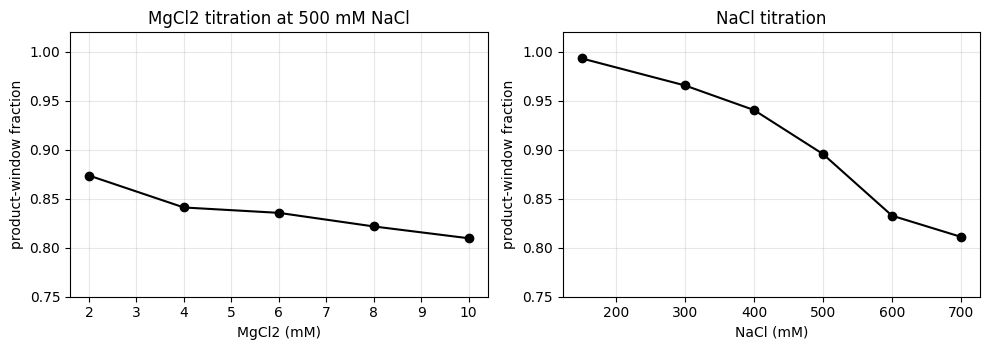

In [5]:
mg_series = ["2 MgCl2, 500 NaCl", "4 MgCl2, 500 NaCl", "6 MgCl2, 500 NaCl",
             "8 MgCl2, 500 NaCl", "10 MgCl2, 500 NaCl"]
na_series = ["150 NaCl", "300 NaCl", "400 NaCl", "500 NaCl", "600 NaCl", "700 NaCl"]

def series(labels, xs, name):
    frame = product.set_index("label").loc[labels]
    return pd.DataFrame({"x": xs, "product_fraction": frame.product_fraction.values, "series": name})

mg = series(mg_series, [2, 4, 6, 8, 10], "MgCl2 (mM), 500 mM NaCl")
na = series(na_series, [150, 300, 400, 500, 600, 700], "NaCl (mM)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, frame, xlabel in ((axes[0], mg, "MgCl2 (mM)"), (axes[1], na, "NaCl (mM)")):
    ax.plot(frame.x, frame.product_fraction, "o-", color="black")
    ax.set(xlabel=xlabel, ylabel="product-window fraction", ylim=(0.75, 1.02))
    ax.grid(alpha=0.3)
axes[0].set_title("MgCl2 titration at 500 mM NaCl")
axes[1].set_title("NaCl titration")
fig.tight_layout()
plt.show()

Both titrations fall monotonically. Whatever that window holds, its share is being traded
for the slower-migrating cluster in a smooth, dose-dependent way across both series.

Treat that as a reason for a second gel rather than a conclusion from this one: these are
single-lane measurements with no replicates, the product window was chosen by eye off the fit
figures, and every lane's decomposition is mildly over-complete (coverage runs 0.999-1.037),
so the fractions carry a percent or two of systematic slack on top of the fit uncertainty.


## Bar chart of everything

For a lab-notebook figure, all 20 conditions sorted by yield, with the low-confidence lanes
marked so nobody quotes one by accident.


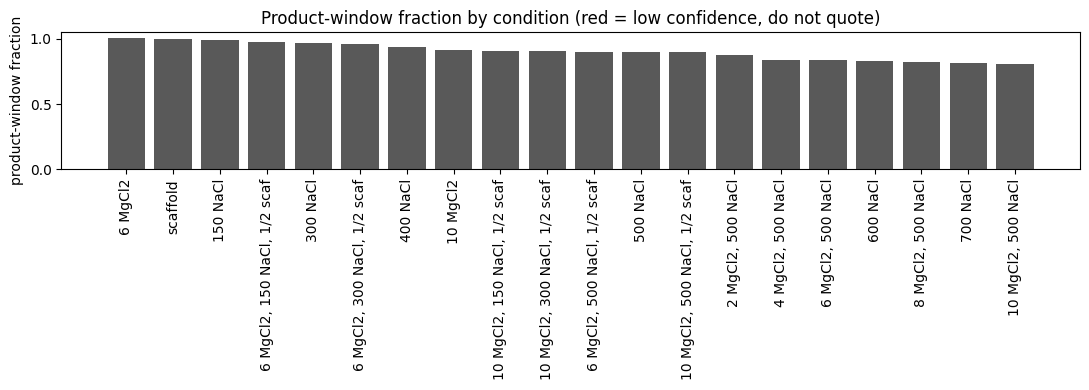

In [6]:
ranked = product.merge(per_lane[["lane_index", "confidence"]], on="lane_index")
ranked = ranked.sort_values("product_fraction", ascending=False)

fig, ax = plt.subplots(figsize=(11, 4))
colors = ["0.35" if c == "ok" else "tab:red" for c in ranked.confidence]
ax.bar(range(len(ranked)), ranked.product_fraction, color=colors)
ax.set_xticks(range(len(ranked)))
ax.set_xticklabels(ranked.label, rotation=90)
ax.set(ylabel="product-window fraction", ylim=(0, 1.05))
ax.set_title("Product-window fraction by condition (red = low confidence, do not quote)")
fig.tight_layout()
plt.show()

## Where to go from here

- `results.json` carries the same content with full nesting, including per-band fit parameters
  and the baseline that was subtracted
- `AnalysisResult.to_dataframe()` gives you this frame directly from Python if you would
  rather not go via CSV
- [`../docs/guide/results.md`](../docs/guide/results.md) documents every column
- [`../docs/guide/known-limitations.md`](../docs/guide/known-limitations.md) is worth reading
  before any of these numbers reach a figure caption
